# PRÁCTICA 1 · ¿Cuánto se quemó en Chichas?

**Reto A · Otro incendio.** Medir el área quemada de un incendio activo del Perú en octubre de 2026 con el índice **dNBR** de Sentinel-2.

| | |
|---|---|
| **Curso** | Ciencia de Datos con Python (Python Intermedio) · Tarea práctica de raster |
| **Estudiante** | Cristian Moises Wong Pagan |
| **Fecha** | 21 de octubre de 2026 |
| **Incendio** | Chichas, provincia de Condesuyos, Arequipa |

**Pregunta:** ¿cuántas hectáreas quemó el incendio de Chichas entre el 16 y el 18 de octubre de 2026, y con qué severidad?

**Procedimiento (6 pasos):**
1. Descargar los focos de calor VIIRS de los últimos 7 días (NASA FIRMS) y quedarnos con los del Perú.
2. Agrupar los focos en incendios (focos a ≤ 1 km) y elegir el incendio.
3. Buscar imágenes Sentinel-2 L2A en Microsoft Planetary Computer y medir el % de nubes **en la zona** con la capa SCL.
4. Calcular NBR antes y después, y su diferencia dNBR, con máscara de nubes.
5. Clasificar la severidad (umbrales USGS) y calcular las hectáreas.
6. Mapas, hallazgos y limitaciones.

Todo corre en CPU, sin claves ni pagos.

## 0. Librerías y parámetros

- `pandas`, `numpy`: tablas y cálculos.
- `shapely`, `scikit-learn`: ubicar focos en distritos y agruparlos en incendios (DBSCAN).
- `pystac-client`, `planetary-computer`: buscar y firmar las imágenes Sentinel-2.
- `rasterio`: leer solo la ventana del incendio desde los archivos COG en la nube.
- `matplotlib`: mapas.

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import requests
from shapely.geometry import shape, Point
from shapely import STRtree
from sklearn.cluster import DBSCAN
from scipy import ndimage
import pystac_client, planetary_computer
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds, transform as warp_transform, transform_geom
from rasterio.features import rasterize
from rasterio.enums import Resampling

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DATOS = Path("datos"); DATOS.mkdir(exist_ok=True)
SALIDAS = Path("salidas"); SALIDAS.mkdir(exist_ok=True)

FECHA_CORTE = "2026-10-21"      # dato más reciente que usamos
EPS_KM = 1.0                    # focos a <= 1 km forman un incendio
BUFFER_M = 2000                 # margen alrededor del incendio para leer la imagen
UMBRAL_QUEMADO = 0.27           # dNBR >= 0.27: quemado (severidad moderada-baja o más)
NUBE_MAX = 5.0                  # % máximo de nubes en la zona para aceptar una imagen
print("rasterio", rasterio.__version__, "| GDAL", rasterio.__gdal_version__)

rasterio 1.5.2 | GDAL 3.12.2


## 1. Focos de calor VIIRS de los últimos 7 días

NASA FIRMS publica, sin clave, un CSV con los focos de los **últimos 7 días** para Sudamérica de cada satélite VIIRS: **S-NPP**, **NOAA-20** y **NOAA-21**. Cada foco es un píxel de 375 m donde el satélite detectó fuego. Usamos los tres satélites para tener más pasadas por día.

Si el archivo ya está en `datos/`, se reutiliza para que el notebook sea reproducible.

In [2]:
FIRMS = "https://firms.modaps.eosdis.nasa.gov/data/active_fire"
ARCHIVOS = {
    "S-NPP":   "suomi-npp-viirs-c2/csv/SUOMI_VIIRS_C2_South_America_7d.csv",
    "NOAA-20": "noaa-20-viirs-c2/csv/J1_VIIRS_C2_South_America_7d.csv",
    "NOAA-21": "noaa-21-viirs-c2/csv/J2_VIIRS_C2_South_America_7d.csv",
}
partes = []
for sat, ruta in ARCHIVOS.items():
    local = DATOS / Path(ruta).name
    if not local.exists():
        local.write_bytes(requests.get(f"{FIRMS}/{ruta}", timeout=120).content)
    d = pd.read_csv(local)
    d["sat"] = sat
    partes.append(d)
focos_sa = pd.concat(partes, ignore_index=True)
print(f"Focos en Sudamérica: {len(focos_sa):,} | del {focos_sa.acq_date.min()} al {focos_sa.acq_date.max()}")
focos_sa.groupby("sat").size()

Focos en Sudamérica: 181,328 | del 2026-10-14 al 2026-10-21


sat
NOAA-20    61575
NOAA-21    60059
S-NPP      59694
dtype: int64

### 1.1 Quedarnos con los focos del Perú

Primero un filtro rápido por el rectángulo del Perú y luego un cruce exacto con los **polígonos de distritos del INEI** (repositorio `juaneladio/peru-geojson`). Así cada foco queda con su distrito, provincia y departamento.

In [3]:
GEO = "https://raw.githubusercontent.com/juaneladio/peru-geojson/master/peru_distrital_simple.geojson"
geo_local = DATOS / "peru_distrital_simple.geojson"
if not geo_local.exists():
    geo_local.write_bytes(requests.get(GEO, timeout=120).content)
gj = json.load(open(geo_local, encoding="utf-8"))
feats = [ft for ft in gj["features"] if ft["geometry"]]
geoms = [shape(ft["geometry"]) for ft in feats]
props = [ft["properties"] for ft in feats]

f = focos_sa[focos_sa.latitude.between(-18.5, 0.1) & focos_sa.longitude.between(-81.5, -68.5)].copy()
arbol = STRtree(geoms)
i_pt, i_geo = arbol.query([Point(x, y) for x, y in zip(f.longitude, f.latitude)], predicate="within")
f = f.iloc[i_pt].copy()
f["distrito"] = [props[i]["NOMBDIST"] for i in i_geo]
f["provincia"] = [props[i]["NOMBPROV"] for i in i_geo]
f["departamento"] = [props[i]["NOMBDEP"] for i in i_geo]
print(f"Focos en el Perú: {len(f):,}")
f.groupby("departamento").size().sort_values(ascending=False).head(10).rename("focos")

Focos en el Perú: 9,949


departamento
UCAYALI       2369
JUNIN         1331
HUANUCO        929
LORETO         854
CUSCO          676
AREQUIPA       533
APURIMAC       506
SAN MARTIN     417
ANCASH         370
AYACUCHO       267
Name: focos, dtype: int64

## 2. De focos a incendios

Un foco no es un incendio. Agrupamos con **DBSCAN** (distancia haversine): focos a ≤ 1 km entre sí forman un mismo incendio, y pedimos al menos 3 focos para descartar detecciones sueltas. Luego ordenamos los incendios por número de focos.

In [4]:
X = np.radians(f[["latitude", "longitude"]].values)
f["incendio"] = DBSCAN(eps=EPS_KM / 6371.0, min_samples=3, metric="haversine").fit(X).labels_
moda = lambda s: s.mode().iloc[0]
incendios = (f[f.incendio >= 0].groupby("incendio")
    .agg(focos=("frp", "size"), frp_total_MW=("frp", "sum"), lat=("latitude", "mean"), lon=("longitude", "mean"),
         primer_dia=("acq_date", "min"), ultimo_dia=("acq_date", "max"),
         distrito=("distrito", moda), provincia=("provincia", moda), departamento=("departamento", moda))
    .sort_values("focos", ascending=False).reset_index())
print(f"Incendios (>= 3 focos) en los últimos 7 días: {len(incendios)}")
incendios.head(10).round(3)

Incendios (>= 3 focos) en los últimos 7 días: 839


,incendio,focos,frp_total_MW,lat,lon,primer_dia,ultimo_dia,distrito,provincia,departamento
0,23,295,2366.37,-11.840,-73.865,2026-10-14,2026-10-20,RIO TAMBO,SATIPO,JUNIN
1,32,222,3011.27,-13.640,-72.424,2026-10-14,2026-10-20,CURAHUASI,ABANCAY,APURIMAC
2,542,198,1979.25,-15.486,-72.985,2026-10-16,2026-10-18,CHICHAS,CONDESUYOS,AREQUIPA
3,107,134,2230.57,-8.479,-74.536,2026-10-14,2026-10-16,MANANTAY,CORONEL PORTILLO,UCAYALI
4,109,122,6671.11,-9.619,-73.790,2026-10-15,2026-10-16,TAHUANIA,ATALAYA,UCAYALI
5,34,104,1971.04,-13.735,-72.133,2026-10-14,2026-10-17,HUANOQUITE,PARURO,CUSCO
6,655,92,808.48,-16.701,-71.809,2026-10-17,2026-10-21,LA JOYA,AREQUIPA,AREQUIPA
7,118,78,639.85,-11.782,-74.075,2026-10-14,2026-10-20,MAZAMARI,SATIPO,JUNIN
8,589,78,1490.73,-10.247,-76.348,2026-10-18,2026-10-20,CAYNA,AMBO,HUANUCO
9,105,77,1393.40,-8.130,-75.002,2026-10-15,2026-10-21,NUEVA REQUENA,CORONEL PORTILLO,UCAYALI


### 2.1 Elección del incendio: Chichas (Arequipa)

Elegimos **Chichas** por tres razones:
- Es el **3.er incendio más grande** de la semana por número de focos y uno de los sugeridos en clase.
- Está en la **zona andina seca de Arequipa**, donde casi no hay nubes en octubre. Río Tambo (Junín) y Manantay (Ucayali) están en selva, con nubes frecuentes y humo.
- Curahuasi ya fue analizado por el profesor.

In [5]:
fuego = incendios[incendios.distrito == "CHICHAS"].iloc[0]
focos_fuego = f[f.incendio == fuego.incendio].copy()
print(fuego.to_string())
focos_fuego.groupby(["acq_date", "sat"]).size().unstack(fill_value=0)

incendio               542
focos                  198
frp_total_MW       1979.25
lat             -15.485846
lon             -72.985082
primer_dia      2026-10-16
ultimo_dia      2026-10-18
distrito           CHICHAS
provincia       CONDESUYOS
departamento      AREQUIPA


sat,NOAA-20,NOAA-21,S-NPP
acq_date,,,
2026-10-16,6,0,0
2026-10-17,27,49,34
2026-10-18,22,26,34


## 3. Imágenes Sentinel-2 L2A

Buscamos en el catálogo STAC de **Microsoft Planetary Computer** (colección `sentinel-2-l2a`, 10–20 m, reflectancia de superficie) todas las imágenes del 1 al 21 de octubre que cubren el incendio.

La zona de estudio es el rectángulo de los focos más un margen de 2 km, en la proyección UTM de la imagen (EPSG:32718).

In [6]:
lon0, lat0 = focos_fuego.longitude.min(), focos_fuego.latitude.min()
lon1, lat1 = focos_fuego.longitude.max(), focos_fuego.latitude.max()
bbox_ll = [lon0 - 0.03, lat0 - 0.03, lon1 + 0.03, lat1 + 0.03]

catalogo = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                     modifier=planetary_computer.sign_inplace)
items = catalogo.search(collections=["sentinel-2-l2a"], bbox=bbox_ll,
                        datetime=f"2026-10-01/{FECHA_CORTE}").item_collection()
# El incendio cae en la tesela 18LYH: nos quedamos con ella para que todas las imágenes compartan la misma grilla
items = [it for it in items if it.properties["s2:mgrs_tile"] == "18LYH"]
items = sorted(items, key=lambda it: it.datetime)
CRS = f"EPSG:{items[0].properties['proj:code'].split(':')[-1]}" if "proj:code" in items[0].properties else f"EPSG:{items[0].properties['proj:epsg']}"

# Zona de estudio en UTM, ajustada a la grilla de 20 m
xs, ys = warp_transform("EPSG:4326", CRS, [lon0, lon1], [lat0, lat1])
x0, x1 = min(xs) - BUFFER_M, max(xs) + BUFFER_M
y0, y1 = min(ys) - BUFFER_M, max(ys) + BUFFER_M
x0, y0 = np.floor(x0 / 20) * 20, np.floor(y0 / 20) * 20
x1, y1 = np.ceil(x1 / 20) * 20, np.ceil(y1 / 20) * 20
BOUNDS = (x0, y0, x1, y1)
W, H = int((x1 - x0) / 20), int((y1 - y0) / 20)
print(f"CRS {CRS} | zona {W*20/1000:.1f} km x {H*20/1000:.1f} km = {W*H*0.04:,.0f} ha | {W} x {H} píxeles de 20 m")
pd.DataFrame([{"fecha": it.datetime.strftime("%Y-%m-%d %H:%M UTC"), "id": it.id,
               "nubes_tesela_%": round(it.properties["eo:cloud_cover"], 1)} for it in items])

CRS EPSG:32718 | zona 10.9 km x 11.5 km = 12,446 ha | 543 x 573 píxeles de 20 m


,fecha,id,nubes_tesela_%
0,2026-10-03 15:07 UTC,S2B_MSIL2A_20261003T150719_R082_T18LYH_2026100...,0.0
1,2026-10-05 14:57 UTC,S2C_MSIL2A_20261005T145731_R039_T18LYH_2026100...,0.1
2,2026-10-07 14:59 UTC,S2A_MSIL2A_20261007T145941_R039_T18LYH_2026100...,0.2
3,2026-10-08 15:07 UTC,S2C_MSIL2A_20261008T150721_R082_T18LYH_2026100...,0.4
4,2026-10-10 14:57 UTC,S2B_MSIL2A_20261010T145729_R039_T18LYH_2026101...,0.0
5,2026-10-10 15:07 UTC,S2A_MSIL2A_20261010T150731_R082_T18LYH_2026101...,0.0
6,2026-10-13 15:07 UTC,S2B_MSIL2A_20261013T150719_R082_T18LYH_2026101...,2.6
7,2026-10-15 14:57 UTC,S2C_MSIL2A_20261015T145731_R039_T18LYH_2026101...,0.3
8,2026-10-17 14:57 UTC,S2A_MSIL2A_20261017T145731_R039_T18LYH_2026101...,0.1
9,2026-10-18 15:07 UTC,S2C_MSIL2A_20261018T150721_R082_T18LYH_2026101...,0.0


### 3.1 % de nubes en la zona del incendio (capa SCL)

El `eo:cloud_cover` del catálogo es el % de nubes de **toda la tesela** (110 × 110 km). Lo que importa es la nube **sobre el incendio**. Para eso leemos solo nuestra ventana de la capa **SCL** (clasificación de escena) y contamos los píxeles de nube (8, 9), cirros (10) y sombra de nube (3).

Leer solo la ventana es posible porque los archivos son **COG** (Cloud Optimized GeoTIFF): `rasterio` descarga únicamente los bloques necesarios.

In [7]:
def leer(item, banda, resampling=Resampling.bilinear):
    # Lee una banda solo en la zona de estudio, remuestreada a la grilla de 20 m
    with rasterio.open(item.assets[banda].href) as src:
        win = from_bounds(*BOUNDS, transform=src.transform)
        return src.read(1, window=win, out_shape=(H, W), resampling=resampling)

NUBES_SCL = [3, 8, 9, 10]
filas = []
for it in items:
    scl = leer(it, "SCL", Resampling.nearest)
    valido = scl > 0
    filas.append({"fecha": it.datetime.date().isoformat(), "hora_utc": it.datetime.strftime("%H:%M"),
                  "nubes_zona_%": round(100 * np.isin(scl, NUBES_SCL).sum() / max(valido.sum(), 1), 2),
                  "sin_datos_%": round(100 * (~valido).mean(), 1), "item": it})
escenas = pd.DataFrame(filas)
escenas.drop(columns="item")

,fecha,hora_utc,nubes_zona_%,sin_datos_%
0,2026-10-03,15:07,0.00,0.0
1,2026-10-05,14:57,0.00,0.0
2,2026-10-07,14:59,0.00,0.0
3,2026-10-08,15:07,0.00,0.0
4,2026-10-10,14:57,0.00,0.0
5,2026-10-10,15:07,0.00,0.0
6,2026-10-13,15:07,0.00,0.0
7,2026-10-15,14:57,0.00,0.0
8,2026-10-17,14:57,0.06,0.0
9,2026-10-18,15:07,0.00,0.0


### 3.2 Elegimos la imagen *antes* y la imagen *después*

- **Antes:** la última imagen anterior al primer foco (16 de octubre) con ≤ 5 % de nubes en la zona y sin huecos.
- **Después:** la imagen **más reciente** posterior al último foco (18 de octubre) con ≤ 5 % de nubes en la zona. Si ninguna cumple, se usa la del mismo día del último foco.

In [8]:
ok = escenas[(escenas["nubes_zona_%"] <= NUBE_MAX) & (escenas["sin_datos_%"] < 1)]
antes = ok[ok.fecha < fuego.primer_dia].iloc[-1]
candidatas = ok[ok.fecha > fuego.ultimo_dia]
despues = candidatas.iloc[-1] if len(candidatas) else ok[ok.fecha >= fuego.ultimo_dia].iloc[-1]
print(f"ANTES:   {antes.fecha} {antes.hora_utc} UTC | nubes en la zona {antes['nubes_zona_%']} %")
print(f"DESPUÉS: {despues.fecha} {despues.hora_utc} UTC | nubes en la zona {despues['nubes_zona_%']} %")

ANTES:   2026-10-15 14:57 UTC | nubes en la zona 0.0 %
DESPUÉS: 2026-10-20 15:09 UTC | nubes en la zona 1.87 %


## 4. NBR y dNBR

El **NBR** (*Normalized Burn Ratio*) compara el infrarrojo cercano (la vegetación sana lo refleja mucho) con el infrarrojo de onda corta (el suelo quemado lo refleja más):

$$NBR = \frac{NIR - SWIR}{NIR + SWIR} \qquad dNBR = NBR_{antes} - NBR_{después}$$

- NIR = banda **B8A** (865 nm, 20 m), SWIR = banda **B12** (2190 nm, 20 m).
- Desde 2022 los productos L2A traen un desfase de −1000: reflectancia = (ND − 1000) / 10 000.
- Se enmascaran los píxeles con nube, sombra, agua o nieve en **cualquiera** de las dos fechas (SCL 3, 6, 8, 9, 10, 11) y los píxeles sin dato.

In [9]:
def reflectancia(item, banda):
    return (leer(item, banda).astype("float32") - 1000) / 10000

def nbr(item):
    nir, swir = reflectancia(item, "B8A"), reflectancia(item, "B12")
    return (nir - swir) / (nir + swir + 1e-6)

it_a, it_d = antes["item"], despues["item"]
nbr_a, nbr_d = nbr(it_a), nbr(it_d)
scl_a, scl_d = leer(it_a, "SCL", Resampling.nearest), leer(it_d, "SCL", Resampling.nearest)
MALOS = [0, 1, 3, 6, 8, 9, 10, 11]
mascara = np.isin(scl_a, MALOS) | np.isin(scl_d, MALOS)
dnbr = np.where(mascara, np.nan, nbr_a - nbr_d)
print(f"Píxeles enmascarados: {mascara.mean()*100:.2f} %")
print(f"dNBR: mediana {np.nanmedian(dnbr):.3f} | p99 {np.nanpercentile(dnbr, 99):.3f} | máx {np.nanmax(dnbr):.3f}")

Píxeles enmascarados: 1.87 %
dNBR: mediana -0.015 | p99 0.302 | máx 0.515


## 5. Severidad y hectáreas

Clasificamos el dNBR con los umbrales del **USGS** (Key y Benson, 2006). Cada píxel de 20 m mide 400 m² = **0.04 ha**.

Además medimos el área de dos formas, para mostrar cómo cambia el número según la decisión:
- **Toda la zona de estudio:** cualquier píxel con dNBR ≥ 0.27.
- **Cerca de los focos:** solo píxeles con dNBR ≥ 0.27 a ≤ 750 m de un foco VIIRS (dos píxeles VIIRS). Esto evita contar cambios que no son fuego, como cosechas o sombras.
- **Umbral bajo cerca de los focos:** dNBR ≥ 0.10. Los umbrales USGS se calibraron en bosques; en el **pajonal de puna** la vegetación es rala, el NBR de antes ya es bajo y el salto al quemarse es pequeño. Comparamos con la cicatriz que se ve en color verdadero (sección 6).

In [10]:
CLASES = [("Rebrote", -np.inf, -0.10), ("Sin quemar", -0.10, 0.10), ("Baja", 0.10, 0.27),
          ("Moderada-baja", 0.27, 0.44), ("Moderada-alta", 0.44, 0.66), ("Alta", 0.66, np.inf)]
sev = np.full(dnbr.shape, -1, dtype="int8")
for k, (_, lo, hi) in enumerate(CLASES):
    sev[(dnbr >= lo) & (dnbr < hi)] = k

# Distancia de cada píxel al foco VIIRS más cercano
transform = rasterio.transform.from_bounds(*BOUNDS, W, H)
fx, fy = warp_transform("EPSG:4326", CRS, focos_fuego.longitude.tolist(), focos_fuego.latitude.tolist())
filas_px, cols_px = rasterio.transform.rowcol(transform, fx, fy)
raster_focos = np.zeros((H, W), bool)
for r, c in zip(filas_px, cols_px):
    if 0 <= r < H and 0 <= c < W:
        raster_focos[r, c] = True
dist_m = ndimage.distance_transform_edt(~raster_focos) * 20
cerca = dist_m <= 750

HA = 0.04
tabla = pd.DataFrame([{"severidad": n, "dNBR": f"{lo:.2f} a {hi:.2f}".replace("-inf", "−∞").replace("inf", "∞"),
                       "ha_zona": (sev == k).sum() * HA, "ha_cerca_focos": ((sev == k) & cerca).sum() * HA}
                      for k, (n, lo, hi) in enumerate(CLASES)])
quemado = dnbr >= UMBRAL_QUEMADO
ha_zona, ha_cerca = quemado.sum() * HA, (quemado & cerca).sum() * HA
print(f"Área quemada (dNBR >= {UMBRAL_QUEMADO}) en toda la zona: {ha_zona:,.0f} ha")
print(f"Área quemada (dNBR >= {UMBRAL_QUEMADO}) a <= 750 m de focos: {ha_cerca:,.0f} ha")
quemado_bajo = dnbr >= 0.10
ha_cerca_010 = (quemado_bajo & cerca).sum() * HA
print(f"Área quemada (dNBR >= 0.10) a <= 750 m de focos: {ha_cerca_010:,.0f} ha")
tabla.round(1)

Área quemada (dNBR >= 0.27) en toda la zona: 242 ha
Área quemada (dNBR >= 0.27) a <= 750 m de focos: 242 ha
Área quemada (dNBR >= 0.10) a <= 750 m de focos: 1,647 ha


,severidad,dNBR,ha_zona,ha_cerca_focos
0,Rebrote,−∞ a -0.10,859.1,33.5
1,Sin quemar,-0.10 a 0.10,9648.5,2339.1
2,Baja,0.10 a 0.27,1463.4,1405.1
3,Moderada-baja,0.27 a 0.44,241.0,240.7
4,Moderada-alta,0.44 a 0.66,1.1,1.1
5,Alta,0.66 a ∞,0.0,0.0


### 5.1 Hectáreas quemadas por distrito

Rasterizamos los polígonos de distrito sobre la misma grilla de 20 m y sumamos el área quemada cerca de los focos, con los dos umbrales.

In [11]:
cerca_dist = [(i, g) for i, g in enumerate(geoms)
              if g.intersects(shape({"type": "Polygon", "coordinates": [[(bbox_ll[0], bbox_ll[1]), (bbox_ll[2], bbox_ll[1]),
                  (bbox_ll[2], bbox_ll[3]), (bbox_ll[0], bbox_ll[3]), (bbox_ll[0], bbox_ll[1])]]}))]
id_dist = rasterize([(transform_geom("EPSG:4326", CRS, g.__geo_interface__), i + 1) for i, g in cerca_dist],
                    out_shape=(H, W), transform=transform, fill=0, dtype="int32")
def ha_por_distrito(m, nombre):
    return (pd.DataFrame({"i": id_dist[m] - 1})
            .assign(distrito=lambda d: [props[i]["NOMBDIST"] for i in d.i],
                    provincia=lambda d: [props[i]["NOMBPROV"] for i in d.i])
            .groupby(["distrito", "provincia"]).size().mul(HA).rename(nombre))
por_distrito = (pd.concat([ha_por_distrito(quemado_bajo & cerca, "ha_dnbr_010"),
                           ha_por_distrito(quemado & cerca, "ha_dnbr_027")], axis=1)
                .fillna(0).sort_values("ha_dnbr_010", ascending=False).reset_index())
por_distrito.round(1)

,distrito,provincia,ha_dnbr_010,ha_dnbr_027
0,CHICHAS,CONDESUYOS,1118.2,219.3
1,TORO,LA UNION,528.7,22.5


## 6. Mapas

1. Color verdadero **antes** y **después** (B04, B03, B02).
2. **dNBR** con los focos VIIRS encima.
3. **Severidad** según los umbrales USGS.

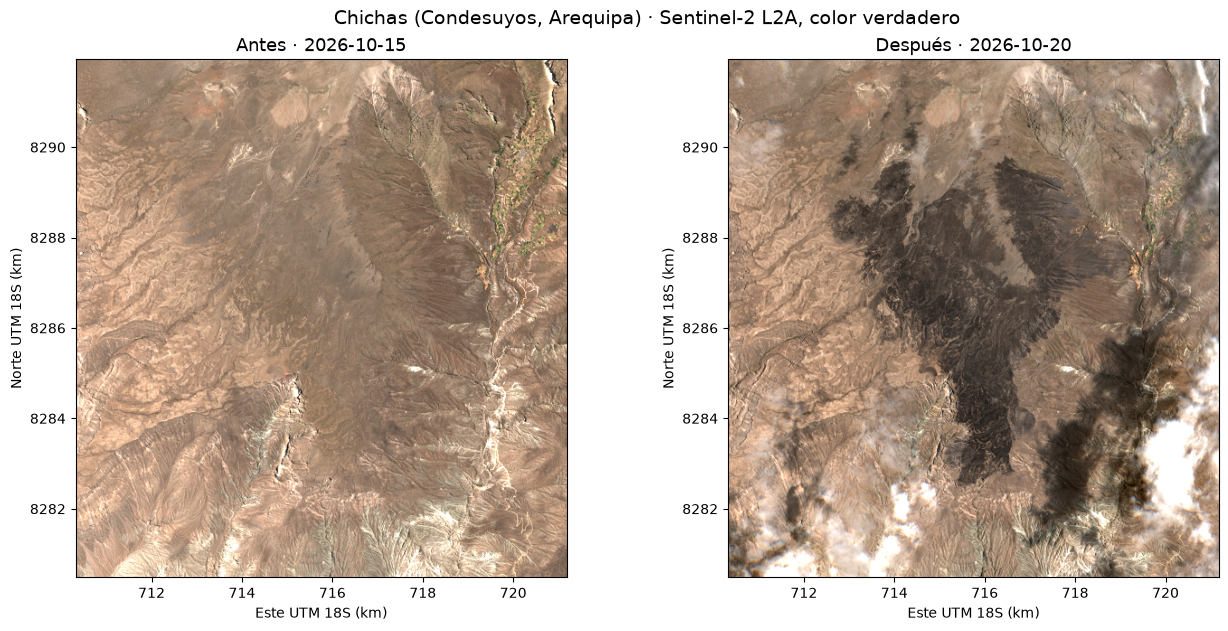

In [12]:
def rgb(item):
    bandas = [reflectancia(item, b) for b in ("B04", "B03", "B02")]
    img = np.dstack(bandas)
    return np.clip(img / 0.30, 0, 1) ** 0.8

rgb_a, rgb_d = rgb(it_a), rgb(it_d)
ext = [x0 / 1000, x1 / 1000, y0 / 1000, y1 / 1000]
fxk, fyk = np.array(fx) / 1000, np.array(fy) / 1000

fig, ax = plt.subplots(1, 2, figsize=(13, 6.2), constrained_layout=True)
for a, img, t in [(ax[0], rgb_a, f"Antes · {antes.fecha}"), (ax[1], rgb_d, f"Después · {despues.fecha}")]:
    a.imshow(img, extent=ext); a.set_title(t, fontsize=13)
    a.set_xlabel("Este UTM 18S (km)"); a.set_ylabel("Norte UTM 18S (km)")
fig.suptitle("Chichas (Condesuyos, Arequipa) · Sentinel-2 L2A, color verdadero", fontsize=14)
fig.savefig(SALIDAS / "rgb_antes_despues.png", dpi=110)
plt.show()

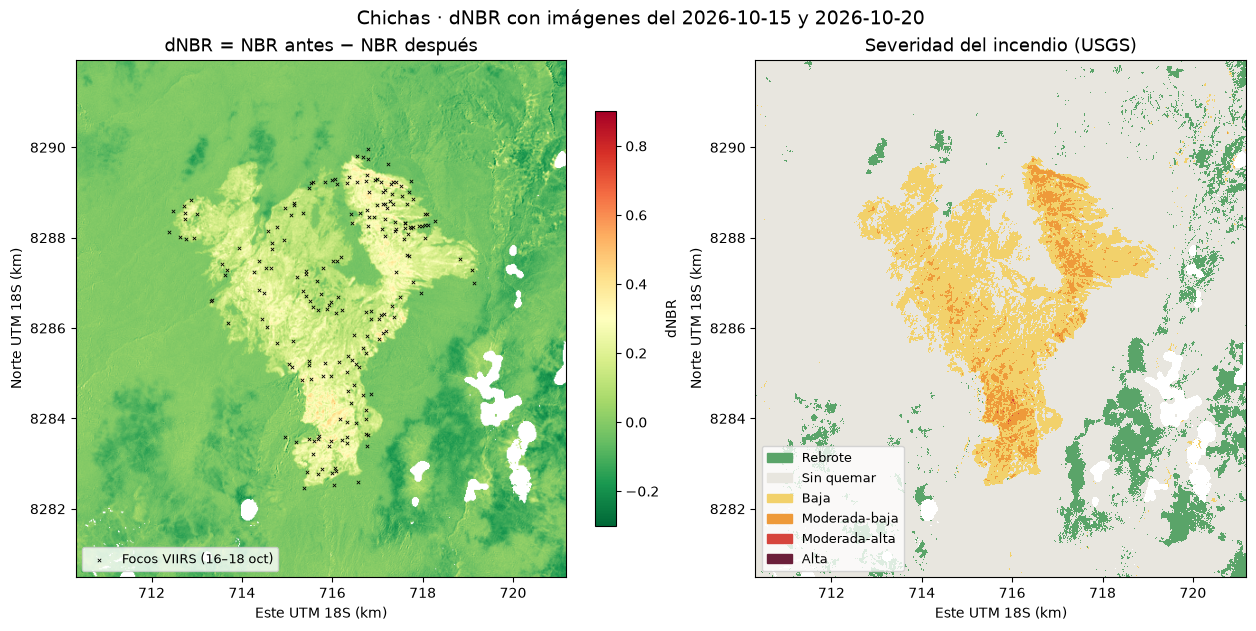

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 6.2), constrained_layout=True)
im = ax[0].imshow(dnbr, extent=ext, cmap="RdYlGn_r", vmin=-0.3, vmax=0.9)
ax[0].scatter(fxk, fyk, s=6, c="black", marker="x", linewidths=0.6, label="Focos VIIRS (16–18 oct)")
ax[0].legend(loc="lower left", fontsize=9); ax[0].set_title("dNBR = NBR antes − NBR después", fontsize=13)
fig.colorbar(im, ax=ax[0], shrink=0.8, label="dNBR")

colores = ["#5aa469", "#e8e6df", "#f2d16b", "#ee9a3a", "#d6453d", "#6b1f3a"]
cmap = ListedColormap(colores)
sev_plot = np.where(sev < 0, np.nan, sev)
ax[1].imshow(sev_plot, extent=ext, cmap=cmap, norm=BoundaryNorm(np.arange(-0.5, 6.5), 6), interpolation="nearest")
ax[1].set_title("Severidad del incendio (USGS)", fontsize=13)
ax[1].legend(handles=[Patch(color=c, label=n) for c, (n, _, _) in zip(colores, CLASES)], loc="lower left", fontsize=9)
for a in ax:
    a.set_xlabel("Este UTM 18S (km)"); a.set_ylabel("Norte UTM 18S (km)")
fig.suptitle(f"Chichas · dNBR con imágenes del {antes.fecha} y {despues.fecha}", fontsize=14)
fig.savefig(SALIDAS / "dnbr_severidad.png", dpi=110)
plt.show()

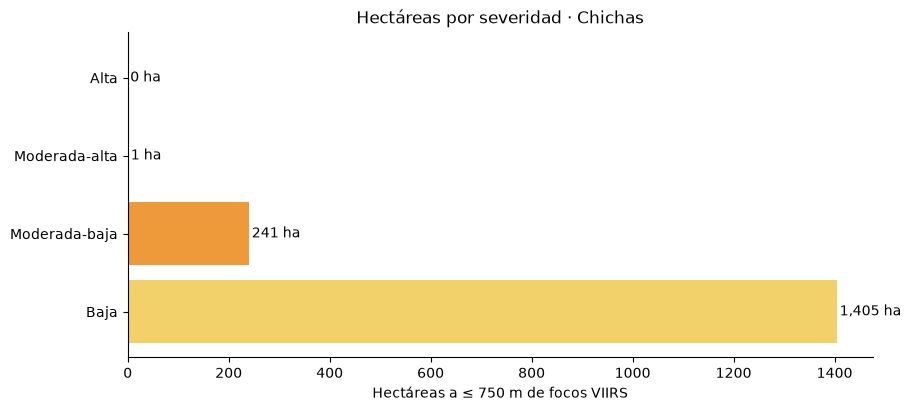

In [14]:
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
t = tabla[tabla.severidad.isin(["Baja", "Moderada-baja", "Moderada-alta", "Alta"])]
ax.barh(t.severidad, t.ha_cerca_focos, color=colores[2:])
for y, v in enumerate(t.ha_cerca_focos):
    ax.text(v + 5, y, f"{v:,.0f} ha", va="center")
ax.set_xlabel("Hectáreas a ≤ 750 m de focos VIIRS"); ax.set_title("Hectáreas por severidad · Chichas")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(SALIDAS / "hectareas_severidad.png", dpi=110)
plt.show()

## 7. Resultados para el dashboard

Guardamos las cifras en `salidas/resultados.json` para la página web que se comparte con el curso.

In [15]:
res = {
    "fecha_corte": FECHA_CORTE,
    "focos_peru_7d": int(len(f)), "incendios_peru_7d": int(len(incendios)),
    "periodo_focos": [focos_sa.acq_date.min(), focos_sa.acq_date.max()],
    "incendio": {"distrito": fuego.distrito, "provincia": fuego.provincia, "departamento": fuego.departamento,
                 "focos": int(fuego.focos), "frp_total_MW": round(float(fuego.frp_total_MW), 1),
                 "primer_dia": fuego.primer_dia, "ultimo_dia": fuego.ultimo_dia,
                 "lat": round(float(fuego.lat), 4), "lon": round(float(fuego.lon), 4),
                 "rank_semana": int(incendios.index[incendios.incendio == fuego.incendio][0]) + 1},
    "focos_por_dia": focos_fuego.groupby("acq_date").size().to_dict(),
    "antes": {"fecha": antes.fecha, "hora_utc": antes.hora_utc, "nubes_zona": float(antes["nubes_zona_%"]), "id": it_a.id},
    "despues": {"fecha": despues.fecha, "hora_utc": despues.hora_utc, "nubes_zona": float(despues["nubes_zona_%"]), "id": it_d.id},
    "zona_ha": round(W * H * HA), "zona_km": [round(W * 0.02, 1), round(H * 0.02, 1)],
    "enmascarado_pct": round(float(mascara.mean() * 100), 2),
    "ha_quemadas_zona": round(float(ha_zona), 1), "ha_quemadas_cerca": round(float(ha_cerca), 1),
    "ha_quemadas_cerca_010": round(float(ha_cerca_010), 1),
    "dnbr_mediana_cicatriz": round(float(np.nanmedian(dnbr[quemado_bajo & cerca])), 3),
    "severidad": tabla.round(1).to_dict(orient="records"),
    "por_distrito": por_distrito.round(1).to_dict(orient="records"),
    "top_incendios": incendios.head(10)[["focos", "frp_total_MW", "distrito", "provincia", "departamento", "primer_dia", "ultimo_dia"]]
                     .round(1).to_dict(orient="records"),
    "escenas": escenas.drop(columns="item").to_dict(orient="records"),
}
(SALIDAS / "resultados.json").write_text(json.dumps(res, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(json.dumps({k: res[k] for k in ["ha_quemadas_cerca_010", "ha_quemadas_cerca", "ha_quemadas_zona", "antes", "despues"]}, indent=2, ensure_ascii=False))

{
  "ha_quemadas_cerca_010": 1646.9,
  "ha_quemadas_cerca": 241.8,
  "ha_quemadas_zona": 242.0,
  "antes": {
    "fecha": "2026-10-15",
    "hora_utc": "14:57",
    "nubes_zona": 0.0,
    "id": "S2C_MSIL2A_20261015T145731_R039_T18LYH_20261015T175103"
  },
  "despues": {
    "fecha": "2026-10-20",
    "hora_utc": "15:09",
    "nubes_zona": 1.87,
    "id": "S2A_MSIL2A_20261020T150931_R082_T18LYH_20261020T222456"
  }
}


## 8. Tres hallazgos con números

In [16]:
d0 = por_distrito.iloc[0]
pct_bm = 100 * (tabla.set_index("severidad").loc[["Baja", "Moderada-baja"], "ha_cerca_focos"].sum()) / max(ha_cerca_010, 1)
print(f'''1. Chichas fue el incendio n.° {res['incendio']['rank_semana']} del Perú por número de focos entre el {res['periodo_focos'][0]} y el {res['periodo_focos'][1]}:
   {res['incendio']['focos']} focos VIIRS en 3 días (pico de {max(res['focos_por_dia'].values())} focos el 17 de octubre), de {res['focos_peru_7d']:,} focos y {res['incendios_peru_7d']} incendios en todo el país.

2. El área quemada depende del umbral: {ha_cerca_010:,.0f} ha con dNBR >= 0.10 frente a {ha_cerca:,.0f} ha con el umbral clásico de 0.27
   ({ha_cerca_010/ha_cerca:.1f} veces más). La cicatriz que se ve en color verdadero coincide con la primera cifra: en el pajonal de puna
   la mediana del dNBR dentro de la cicatriz es solo {res['dnbr_mediana_cicatriz']:.2f}.

3. Es un incendio extenso pero de baja severidad: el {pct_bm:.0f} % del área quemada es de severidad baja o moderada-baja y casi no hay
   severidad alta. El {100*d0.ha_dnbr_010/ha_cerca_010:.0f} % está en el distrito de {d0.distrito.title()} ({d0.ha_dnbr_010:,.0f} ha); el resto, en distritos vecinos.''')

1. Chichas fue el incendio n.° 3 del Perú por número de focos entre el 2026-10-14 y el 2026-10-21:
   198 focos VIIRS en 3 días (pico de 110 focos el 17 de octubre), de 9,949 focos y 839 incendios en todo el país.

2. El área quemada depende del umbral: 1,647 ha con dNBR >= 0.10 frente a 242 ha con el umbral clásico de 0.27
   (6.8 veces más). La cicatriz que se ve en color verdadero coincide con la primera cifra: en el pajonal de puna
   la mediana del dNBR dentro de la cicatriz es solo 0.18.

3. Es un incendio extenso pero de baja severidad: el 100 % del área quemada es de severidad baja o moderada-baja y casi no hay
   severidad alta. El 68 % está en el distrito de Chichas (1,118 ha); el resto, en distritos vecinos.


## 9. Limitaciones

1. **Un foco de calor no es un incendio.** Agrupar focos a ≤ 1 km es una decisión de método; otro radio daría otros incendios.
2. **Las nubes esconden el fuego.** La imagen del 20 de octubre tiene nubes al sureste de la zona (enmascaradas con SCL), y algunas **sombras de nube** no las detecta la SCL: aparecen como manchas de "rebrote" que no son reales.
3. **El umbral cambia el resultado** casi 7 veces. Los umbrales USGS se calibraron en bosques templados; para pajonal andino no hay una calibración oficial, así que reportamos las dos cifras.
4. **Resolución de 20 m y fechas.** No se ven quemas pequeñas, y la imagen de antes (15 oct) y la de después (20 oct) están separadas 5 días: parte del cambio podría no ser fuego (sequía, sombras por la hora de paso, que difiere en 10 minutos por estar en órbitas distintas).
5. **Datos preliminares.** Los focos FIRMS de 7 días son de tiempo casi real (versión NRT) y pueden corregirse después. Esta cifra no reemplaza los reportes oficiales del COEN, INDECI, SERFOR o SERNANP.

## 10. Extra · Progresión diaria, relieve y cercanía a poblados

Tres análisis más para el dashboard:
1. **Progresión de la cicatriz:** dNBR con las imágenes intermedias del 17 y 18 de octubre (también sin nubes) y la final del 20 de octubre.
2. **Relieve:** modelo digital de elevación **Copernicus DEM GLO-30** (30 m) desde Planetary Computer: altitud y pendiente del área quemada, y la malla para la vista 3D.
3. **Exposición:** edificaciones, poblados y vías de **OpenStreetMap** (API de OSM, con Overpass como respaldo) y su distancia al área quemada.

In [17]:
from rasterio.warp import reproject
from scipy.spatial import cKDTree
WEB = SALIDAS / "web"; WEB.mkdir(exist_ok=True)

# 10.1 Progresión: cada imagen posterior limpia frente a la imagen de antes (15 oct)
post = escenas[(escenas.fecha > antes.fecha) & (escenas["nubes_zona_%"] <= NUBE_MAX) & (escenas["sin_datos_%"] < 1)]
prog, mascaras = [], []
for _, e in post.iterrows():
    scl_t = leer(e["item"], "SCL", Resampling.nearest)
    d_t = np.where(np.isin(scl_a, MALOS) | np.isin(scl_t, MALOS), np.nan, nbr_a - nbr(e["item"]))
    m = (d_t >= 0.10) & cerca
    mascaras.append(m)
    prog.append({"fecha": e.fecha, "hora_utc": e.hora_utc, "nubes_zona_%": e["nubes_zona_%"],
                 "ha_dnbr_010": round(m.sum() * HA, 1), "ha_dnbr_027": round(((d_t >= 0.27) & cerca).sum() * HA, 1),
                 "focos_hasta_ese_dia": int((focos_fuego.acq_date <= e.fecha).sum())})
progresion = pd.DataFrame(prog)

# Mapa de progresión: fecha de la primera imagen en la que cada píxel aparece quemado
primera = np.full((H, W), -1, "int8")
for k, m in enumerate(mascaras):
    primera[(primera < 0) & m] = k
progresion

,fecha,hora_utc,nubes_zona_%,ha_dnbr_010,ha_dnbr_027,focos_hasta_ese_dia
0,2026-10-17,14:57,0.06,433.1,67.4,116
1,2026-10-18,15:07,0.00,1439.0,62.2,198
2,2026-10-20,15:09,1.87,1646.9,241.8,198


In [18]:
# 10.2 Relieve: Copernicus DEM GLO-30 remuestreado a 40 m sobre la misma zona
H2, W2 = H // 2, W // 2
transform2 = rasterio.transform.from_bounds(*BOUNDS, W2, H2)
b_ll = transform_bounds(CRS, "EPSG:4326", *BOUNDS, densify_pts=21)
dem = np.full((H2, W2), np.nan, "float32")
for it in catalogo.search(collections=["cop-dem-glo-30"], bbox=list(b_ll)).item_collection():
    with rasterio.open(it.assets["data"].href) as src:
        try:
            win = from_bounds(*b_ll, transform=src.transform).intersection(rasterio.windows.Window(0, 0, src.width, src.height))
        except Exception:
            continue
        win = win.round_offsets().round_lengths()
        arr = src.read(1, window=win).astype("float32")
        tmp = np.full((H2, W2), np.nan, "float32")
        reproject(arr, tmp, src_transform=src.window_transform(win), src_crs=src.crs, dst_transform=transform2, dst_crs=CRS,
                  resampling=Resampling.bilinear, src_nodata=src.nodata, dst_nodata=np.nan)
        dem = np.where(np.isnan(dem), tmp, dem)

gy, gx = np.gradient(dem, 40.0)
pendiente = np.degrees(np.arctan(np.hypot(gx, gy)))
quemado_final = mascaras[-1]
q2 = quemado_final[:H2 * 2:2, :W2 * 2:2]
r2, c2 = rasterio.transform.rowcol(transform2, fx, fy)
z_focos = np.array([dem[r, c] if 0 <= r < H2 and 0 <= c < W2 else np.nan for r, c in zip(r2, c2)])
bandas = (dem[q2] // 100 * 100).astype(int)
altitud_ha = pd.Series(bandas).value_counts().sort_index().mul(0.16)   # píxel de 40 m = 0.16 ha
print(f"Altitud de la zona: {np.nanmin(dem):,.0f} a {np.nanmax(dem):,.0f} m s. n. m.")
print(f"Altitud del área quemada: {np.nanpercentile(dem[q2], 5):,.0f} a {np.nanpercentile(dem[q2], 95):,.0f} m (p5–p95), mediana {np.nanmedian(dem[q2]):,.0f} m")
print(f"Altitud de los focos: mediana {np.nanmedian(z_focos):,.0f} m | pendiente media del área quemada {np.nanmean(pendiente[q2]):.1f}° (zona: {np.nanmean(pendiente):.1f}°)")
altitud_ha.rename("ha_quemadas").to_frame().T

Altitud de la zona: 1,616 a 4,676 m s. n. m.
Altitud del área quemada: 3,287 a 4,091 m (p5–p95), mediana 3,783 m
Altitud de los focos: mediana 3,720 m | pendiente media del área quemada 20.0° (zona: 26.2°)


,-9223372036854775808,2600,2700,2800,2900,3000,3100,3200,3300,3400,3500,3600,3700,3800,3900,4000,4100,4200
ha_quemadas,4.8,0.64,7.2,8.8,9.92,11.84,17.92,31.2,52.32,74.88,95.2,259.84,308.64,318.88,246.72,130.56,61.76,9.44


In [19]:
# 10.3 OpenStreetMap: edificaciones, poblados y vías en un radio de ~6 km (API de OSM; Overpass como respaldo)
s_, w_, n_, e_ = b_ll[1] - 0.06, b_ll[0] - 0.06, b_ll[3] + 0.06, b_ll[2] + 0.06
q = (f'[out:json][timeout:90];(way["building"]({s_},{w_},{n_},{e_});node["building"]({s_},{w_},{n_},{e_});'
     f'node["place"]({s_},{w_},{n_},{e_});way["highway"]({s_},{w_},{n_},{e_}););out geom;')
osm_local = DATOS / "osm_chichas.json"
if not osm_local.exists():
    # Fuente 1: API principal de OSM (/map, recuadros de hasta 0.25 grados²); se convierte al formato de Overpass
    import xml.etree.ElementTree as ET
    try:
        rq = requests.get(f"https://api.openstreetmap.org/api/0.6/map?bbox={w_},{s_},{e_},{n_}", timeout=120,
                          headers={"User-Agent": "TareaDiplomado-Raster/1.0"})
        rq.raise_for_status()
        root = ET.fromstring(rq.content)
        nodos = {n.get("id"): (float(n.get("lon")), float(n.get("lat"))) for n in root.iter("node")}
        els = []
        for n in root.iter("node"):
            tags = {t.get("k"): t.get("v") for t in n.iter("tag")}
            if tags: els.append({"type": "node", "lon": float(n.get("lon")), "lat": float(n.get("lat")), "tags": tags})
        for w in root.iter("way"):
            tags = {t.get("k"): t.get("v") for t in w.iter("tag")}
            if "building" in tags or "highway" in tags:
                geom = [{"lon": nodos[nd.get("ref")][0], "lat": nodos[nd.get("ref")][1]} for nd in w.iter("nd") if nd.get("ref") in nodos]
                if geom: els.append({"type": "way", "tags": tags, "geometry": geom})
        osm_local.write_text(json.dumps({"fuente": "api.openstreetmap.org/api/0.6/map", "elements": els}), encoding="utf-8")
    except Exception as ex:
        print("API de OSM falló:", ex)
if not osm_local.exists():
    # Fuente 2: Overpass API
    for url in ["https://overpass-api.de/api/interpreter", "https://overpass.kumi.systems/api/interpreter"]:
        try:
            rq = requests.post(url, data={"data": q}, timeout=150, headers={"User-Agent": "TareaDiplomado-Raster/1.0"})
            rq.raise_for_status(); osm_local.write_text(rq.text, encoding="utf-8"); break
        except Exception as ex:
            print("Overpass falló en", url, ex)
osm = json.loads(osm_local.read_text(encoding="utf-8"))["elements"] if osm_local.exists() else []

def a_utm(lons, lats):
    xs_, ys_ = warp_transform("EPSG:4326", CRS, list(lons), list(lats))
    return np.array(xs_), np.array(ys_)

# Centros de los píxeles quemados (imagen final) para medir distancias con un árbol KD
rr, cc = np.nonzero(quemado_final)
arbol_q = cKDTree(np.c_[x0 + (cc + 0.5) * 20, y1 - (rr + 0.5) * 20])
edif, lugares, vias = [], [], []
for el in osm:
    tags = el.get("tags", {})
    if "building" in tags:
        if el["type"] == "node": lo, la = [el["lon"]], [el["lat"]]
        else: lo, la = [np.mean([p["lon"] for p in el["geometry"]])], [np.mean([p["lat"] for p in el["geometry"]])]
        bx, by = a_utm(lo, la); edif.append((bx[0], by[0]))
    elif el["type"] == "node" and "place" in tags:
        bx, by = a_utm([el["lon"]], [el["lat"]])
        lugares.append({"nombre": tags.get("name", "(sin nombre)"), "tipo": tags["place"], "x": bx[0], "y": by[0]})
    elif el["type"] == "way" and "highway" in tags:
        bx, by = a_utm([p["lon"] for p in el["geometry"]], [p["lat"] for p in el["geometry"]])
        vias.append({"tipo": tags["highway"], "nombre": tags.get("name", ""), "x": bx, "y": by})

edif = np.array(edif).reshape(-1, 2)
d_edif = arbol_q.query(edif)[0] if len(edif) else np.array([])
lugares = pd.DataFrame(lugares)
if len(lugares):
    lugares["dist_km"] = (arbol_q.query(lugares[["x", "y"]].values)[0] / 1000).round(2)
    lugares = lugares.sort_values("dist_km")
d_vias = [arbol_q.query(np.c_[v["x"], v["y"]])[0].min() for v in vias]
km_vias_1km = sum(np.hypot(np.diff(v["x"]), np.diff(v["y"]))[(arbol_q.query(np.c_[v["x"], v["y"]])[0][:-1] <= 1000)].sum() for v in vias) / 1000
print(f"OSM: {len(edif)} edificaciones, {len(lugares)} poblados, {len(vias)} vías")
print(f"Edificaciones a <= 1 km del área quemada: {(d_edif <= 1000).sum()} | <= 2 km: {(d_edif <= 2000).sum()} | <= 5 km: {(d_edif <= 5000).sum()}")
print(f"Vías a <= 1 km del área quemada: {km_vias_1km:.1f} km")
lugares.drop(columns=["x", "y"]).head(8) if len(lugares) else "Sin poblados en OSM"

OSM: 13 edificaciones, 44 poblados, 42 vías
Edificaciones a <= 1 km del área quemada: 0 | <= 2 km: 0 | <= 5 km: 0
Vías a <= 1 km del área quemada: 16.8 km


,nombre,tipo,dist_km
20,Quichuana,hamlet,0.10
4,Cahuanota,village,0.15
2,Acchapuna,village,0.89
9,Chupacra,hamlet,1.71
41,Ushqui,hamlet,1.95
28,Yanque,village,2.17
14,Huaranguitoyoc,hamlet,2.35
37,Llifllisja,isolated_dwelling,2.68


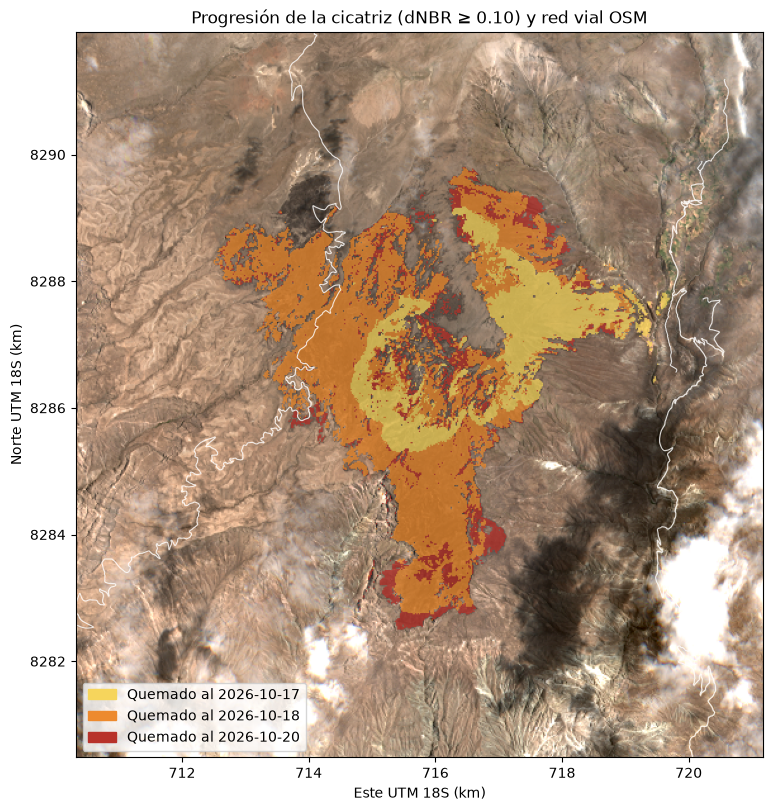

In [20]:
# Mapa de progresión para el notebook
cols_prog = ["#f6d55c", "#ed8a2e", "#b8322a"]
fig, ax = plt.subplots(figsize=(8, 8), constrained_layout=True)
ax.imshow(rgb_d, extent=ext)
ov = np.zeros((H, W, 4))
for k in range(len(mascaras)):
    c = plt.matplotlib.colors.to_rgb(cols_prog[k % 3]); ov[primera == k] = (*c, 0.75)
ax.imshow(ov, extent=ext)
for v in vias:
    ax.plot(v["x"] / 1000, v["y"] / 1000, color="white", lw=0.8, alpha=0.8)
if len(edif): ax.scatter(edif[:, 0] / 1000, edif[:, 1] / 1000, s=6, c="cyan", label="Edificaciones OSM")
ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
ax.legend(handles=[Patch(color=cols_prog[k % 3], label=f"Quemado al {r.fecha}") for k, r in progresion.iterrows()], loc="lower left")
ax.set_title("Progresión de la cicatriz (dNBR ≥ 0.10) y red vial OSM")
ax.set_xlabel("Este UTM 18S (km)"); ax.set_ylabel("Norte UTM 18S (km)")
fig.savefig(SALIDAS / "progresion.png", dpi=110)
plt.show()

In [21]:
# 10.4 Exportar capas y datos para el dashboard web (salidas/web/)
from PIL import Image
def guardar_rgb(item, nombre):
    img = np.dstack([reflectancia_n(item, b) for b in ("B04", "B03", "B02")])
    Image.fromarray((np.clip(img / 0.30, 0, 1) ** 0.8 * 255).astype("uint8")).save(WEB / nombre, quality=85)
    return img
def reflectancia_n(item, banda):
    with rasterio.open(item.assets[banda].href) as src:
        win = from_bounds(*BOUNDS, transform=src.transform)
        return (src.read(1, window=win, out_shape=(H * 2, W * 2), resampling=Resampling.bilinear).astype("float32") - 1000) / 10000
img_d = guardar_rgb(it_d, "rgb_despues.jpg"); guardar_rgb(it_a, "rgb_antes.jpg")

def rgba(mask_colors):
    out = np.zeros((H, W, 4), "uint8")
    for m, hexc in mask_colors:
        out[m] = [int(hexc[i:i + 2], 16) for i in (1, 3, 5)] + [215]
    return out
Image.fromarray(rgba([(primera == k, cols_prog[k % 3]) for k in range(len(mascaras))])).save(WEB / "progresion.png")
Image.fromarray(rgba([(sev == k, c) for k, c in enumerate(colores) if k >= 2])).save(WEB / "severidad.png")

# Textura 3D: color verdadero con la cicatriz final teñida
tex = np.clip(img_d / 0.30, 0, 1) ** 0.8
mq = np.kron(quemado_final, np.ones((2, 2), bool))
tex[mq] = tex[mq] * 0.45 + np.array([0.93, 0.36, 0.16]) * 0.55
Image.fromarray((tex * 255).astype("uint8")).resize((1024, int(1024 * H / W))).save(WEB / "textura_3d.jpg", quality=85)

extra = {
    "W": W * 20, "H": H * 20, "x0": x0, "y1": y1, "crs": CRS, "bbox_ll": list(b_ll),
    "progresion": progresion.to_dict(orient="records"),
    "focos": [{"x": round(px - x0), "y": round(y1 - py), "d": d, "t": f"{int(t):04d}", "s": s, "frp": fr, "n": dn, "z": None if np.isnan(z) else round(float(z))}
              for px, py, d, t, s, fr, dn, z in zip(fx, fy, focos_fuego.acq_date, focos_fuego.acq_time, focos_fuego.sat, focos_fuego.frp, focos_fuego.daynight, z_focos)],
    "dem": {"w": W2, "h": H2, "min": float(np.nanmin(dem)), "max": float(np.nanmax(dem)),
            "z": np.nan_to_num(dem, nan=float(np.nanmin(dem))).round().astype(int).ravel().tolist()},
    "altitud_ha": {int(k): round(float(v), 1) for k, v in altitud_ha.items()},
    "relieve": {"zona_min": float(np.nanmin(dem)), "zona_max": float(np.nanmax(dem)),
                "quemado_p5": float(np.nanpercentile(dem[q2], 5)), "quemado_p95": float(np.nanpercentile(dem[q2], 95)),
                "quemado_mediana": float(np.nanmedian(dem[q2])), "focos_mediana": float(np.nanmedian(z_focos)),
                "pendiente_quemado": float(np.nanmean(pendiente[q2])), "pendiente_zona": float(np.nanmean(pendiente))},
    "osm": {"edificaciones": [[round(a - x0), round(y1 - b), round(float(d))] for (a, b), d in zip(edif, d_edif)],
            "lugares": [] if not len(lugares) else [{"nombre": r.nombre, "tipo": r.tipo, "x": round(r.x - x0), "y": round(y1 - r.y), "dist_km": float(r.dist_km)} for r in lugares.itertuples()],
            "vias": [{"tipo": v["tipo"], "nombre": v["nombre"], "dist_m": round(float(d)), "p": [[round(a - x0), round(y1 - b)] for a, b in zip(v["x"], v["y"])]} for v, d in zip(vias, d_vias)],
            "edif_1km": int((d_edif <= 1000).sum()), "edif_2km": int((d_edif <= 2000).sum()), "edif_5km": int((d_edif <= 5000).sum()),
            "km_vias_1km": round(float(km_vias_1km), 1)},
}
(WEB / "extra.json").write_text(json.dumps(extra, ensure_ascii=False, default=str), encoding="utf-8")
print("Exportado:", sorted(p.name for p in WEB.iterdir()))

Exportado: ['extra.json', 'progresion.png', 'rgb_antes.jpg', 'rgb_despues.jpg', 'severidad.png', 'textura_3d.jpg']
